# Feature Extraction

```
frames.npy (from PreProcessing)
  -> Step 1: KeypointExtractor (MediaPipe Hands) -> (T, 126) per video -> *.npy
  -> Step 2: SequenceBuilder
       a. split videos into train/val/test (stratified by label, before augmentation)
       b. augment the training videos only
       c. pad or crop to 30 frames -> (N, 30, 126) -> .npz
```

Run Step 1 before Step 2.

In [1]:
import sys, os
from pathlib import Path

NOTEBOOK_DIR = Path(os.getcwd())
ROOT = NOTEBOOK_DIR.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print(f'ROOT project: {ROOT}')

ROOT project: D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android


In [2]:
from FeatureExtraction.Config.feature_config import *
create_output_dirs()

[Config] ROOT          : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android
[Config] Dataset       : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Datasets\WLBisindo
[Config] Keypoint Dir  : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Datasets\WLBisindo_Features\keypoints
[Config] Sequence Dir  : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Datasets\WLBisindo_Features\sequences
[Config] Features/frame: 126 (2 hands × 21 kpts × 3 coords)


---
## Step 1: keypoint extraction (MediaPipe Hands)

MediaPipe detects the hands in each frame and returns 21 landmarks per hand.
Output per video: `(T, 126)` = 2 hands x 21 landmarks x 3 coordinates.

Takes about 30-60 minutes for the 1,600 videos on the CPU.

In [3]:
from FeatureExtraction.Scripts.keypoint_extractor import KeypointExtractor

extractor = KeypointExtractor()
extractor.process_all(skip_existing=True)
extractor.close()

[KeypointExtractor] MediaPipe Hands siap.
  max_num_hands      : 2
  detection_conf     : 0.5
  tracking_conf      : 0.5
  normalize_keypoints: True
  features_per_frame : 126
[Config] ROOT          : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android
[Config] Dataset       : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Datasets\WLBisindo
[Config] Keypoint Dir  : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Datasets\WLBisindo_Features\keypoints
[Config] Sequence Dir  : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Datasets\WLBisindo_Features\sequences
[Config] Features/frame: 126 (2 hands × 21 kpts × 3 coords)


Ekstraksi keypoint:   0%|          | 2/1600 [00:01<17:33,  1.52video/s]

  [WARN] signer0_label0_sample10: deteksi rendah (45% frame)


Ekstraksi keypoint:   0%|          | 7/1600 [00:04<16:23,  1.62video/s]

  [WARN] signer0_label0_sample6: deteksi rendah (47% frame)


...

  [WARN] signer4_label9_sample7: deteksi rendah (48% frame)


Ekstraksi keypoint: 100%|█████████▉| 1599/1600 [16:54<00:00,  2.01video/s]

  [WARN] signer4_label9_sample8: deteksi rendah (48% frame)


Ekstraksi keypoint: 100%|██████████| 1600/1600 [16:54<00:00,  1.58video/s]

  [WARN] signer4_label9_sample9: deteksi rendah (48% frame)

[KeypointExtractor] Selesai:
  Diproses   : 1600
  Dilewati   : 0
  Error      : 0
  Low detect : 556 video (< 50% frame terdeteksi)
  Output     : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Datasets\WLBisindo_Features\keypoints


### Step 1 check

Shape     : (34, 126)
Min/Max   : -1.7844 / 2.3600
Terdeteksi: 19/34 frame (55.9%)


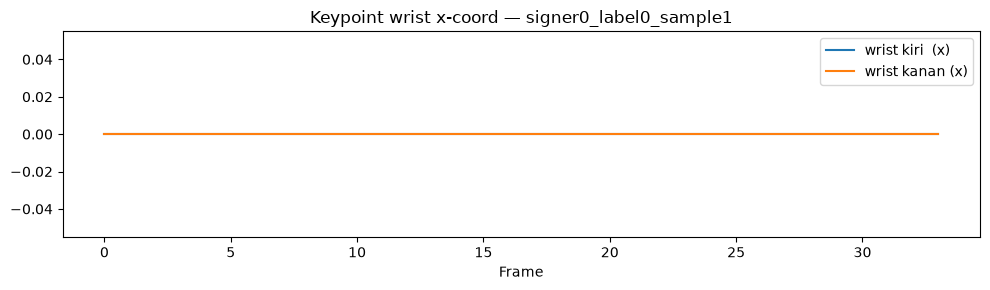

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from FeatureExtraction.Config.feature_config import get_keypoint_path

test_signer, test_label, test_sample = 0, 0, 1
vid_name = f'signer{test_signer}_label{test_label}_sample{test_sample}'
kpt_path = get_keypoint_path(test_signer, test_label, test_sample)

kpts = np.load(kpt_path)  # (T, 126)
print(f'Shape     : {kpts.shape}')
print(f'Min/Max   : {kpts.min():.4f} / {kpts.max():.4f}')

detected = np.any(kpts != 0, axis=1)
print(f'Detected  : {detected.sum()}/{len(kpts)} frames ({detected.mean()*100:.1f}%)')

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(kpts[:, 0],  label='left wrist (x)')
ax.plot(kpts[:, 63], label='right wrist (x)')
ax.set_title(f'Wrist x coordinate, {vid_name}')
ax.set_xlabel('Frame')
ax.legend()
plt.tight_layout()
plt.show()

---
## Step 2: sequence builder

- Split the videos into train/val/test, stratified by label, before augmentation
- Augment the training videos only (see `AUGMENTATION_CONFIG` in `Config/feature_config.py`)
- Pad or crop every sequence to 30 frames
- Save one `.npz` per split

Takes about 1-5 minutes.

In [5]:
from FeatureExtraction.Scripts.sequence_builder import SequenceBuilder, verify_sequences

builder = SequenceBuilder()
builder.build(skip_existing=False)

[Config] ROOT          : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android
[Config] Dataset       : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Datasets\WLBisindo
[Config] Keypoint Dir  : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Datasets\WLBisindo_Features\keypoints
[Config] Sequence Dir  : D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Datasets\WLBisindo_Features\sequences
[Config] Features/frame: 126 (2 hands × 21 kpts × 3 coords)
[SequenceBuilder] Stratified split (video-level, shared dgn MViTv2)...
[SequenceBuilder] Augmentasi: enabled=True, teknik=['horizontal_flip', 'rotation', 'zoom'], multiplier=2x (hanya diterapkan ke train)
[SequenceBuilder] Loading keypoint files...
  [train] 1120 video keypoint loaded


Build train: 100%|██████████| 1120/1120 [00:00<00:00, 12559.98video/s]


  [val  ] 224 video keypoint loaded


Build val: 100%|██████████| 224/224 [00:00<00:00, 89248.99video/s]


  [test ] 256 video keypoint loaded


Build test: 100%|██████████| 256/256 [00:00<00:00, 98753.04video/s]


  [train]  3360 sequences -> D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Datasets\WLBisindo_Features\sequences\train_sequences.npz
  [val  ]   224 sequences -> D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Datasets\WLBisindo_Features\sequences\val_sequences.npz
  [test ]   256 sequences -> D:\Softwares\AnacondaProjects\CNN-LSTM_BISINDO_Android\Datasets\WLBisindo_Features\sequences\test_sequences.npz

[SequenceBuilder] Selesai!

--- Statistik Sequences ---------------------------------------
  train: X=(3360, 30, 126), y=(3360,), labels=32
  val  : X=(224, 30, 126), y=(224,), labels=32
  test : X=(256, 30, 126), y=(256,), labels=32
-----------------------------------------------------------------


In [6]:
verify_sequences()

=== Verifikasi Sequences ===

[train]
  X shape    : (3360, 30, 126)
  y shape    : (3360,)
  X dtype    : float32
  X min/max  : -7.9791 / 6.5355
  y unique   : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31]
  Samples/label (min/max): 105 / 105
  Frame zero  : 41.6% (tangan tidak terdeteksi)

[val]
  X shape    : (224, 30, 126)
  y shape    : (224,)
  X dtype    : float32
  X min/max  : -5.4573 / 4.1806
  y unique   : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31]
  Samples/label (min/max): 7 / 7
  Frame zero  : 40.0% (tangan tidak terdeteksi)

[test]
  X shape    : (256, 30, 126)
  y shape    : (256,)
  X dtype    : float32
  X min/max  : -4.1987 / 4.7200
  y unique   : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31]
  Samples/label (min/max): 8 / 8
  Frame zero  : 43.2% (tangan tidak terdeteksi)

=== Verifikasi Selesai ===


In [7]:
# Original vs augmented sequences in the training split
import numpy as np
from FeatureExtraction.Config.feature_config import get_sequence_output_path

train_data = np.load(get_sequence_output_path('train'), allow_pickle=True)
ids = train_data['ids']
n_original = sum(1 for i in ids if str(i).endswith('_original'))
n_augmented = len(ids) - n_original

print(f"Train sequences : {len(ids)}")
print(f"  Original  : {n_original}")
print(f"  Augmented : {n_augmented}")

Train sequences : 3360
  Original  : 1120
  Augmented : 2240
(val/test tidak boleh punya versi '_aug_' — cek manual jika perlu)


### Label distribution per split

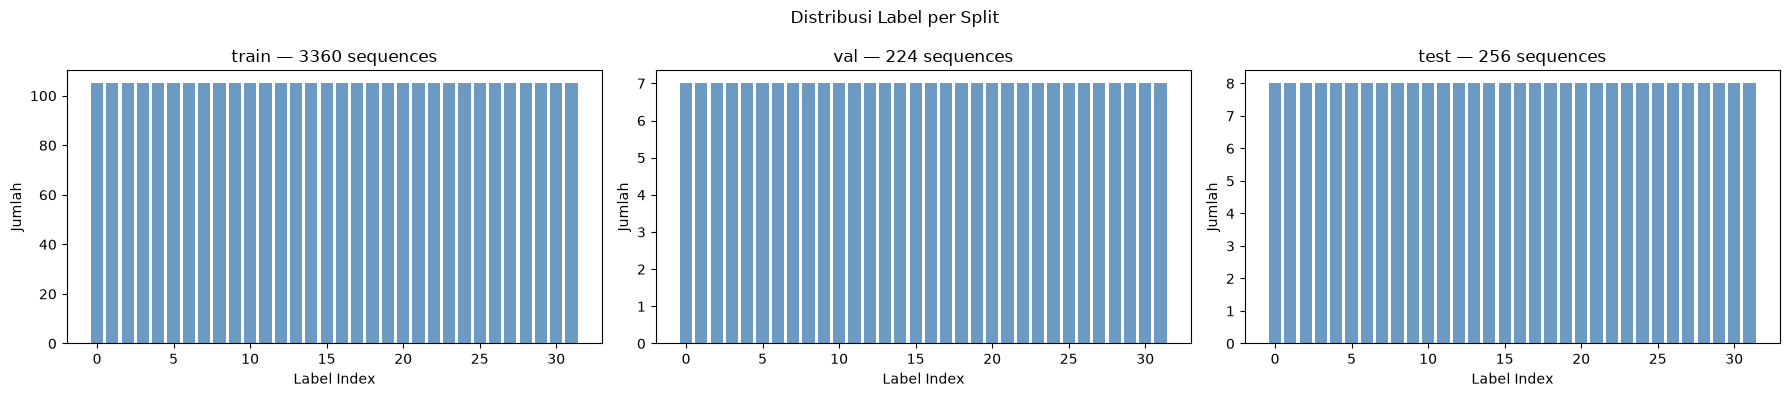

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from FeatureExtraction.Config.feature_config import get_sequence_output_path, NUM_LABELS

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, split in zip(axes, ['train', 'val', 'test']):
    data   = np.load(get_sequence_output_path(split), allow_pickle=True)
    counts = np.bincount(data['y'], minlength=NUM_LABELS)
    ax.bar(range(NUM_LABELS), counts, color='steelblue', alpha=0.8)
    ax.set_title(f'{split}: {len(data["y"])} sequences')
    ax.set_xlabel('Label index')
    ax.set_ylabel('Count')
plt.suptitle('Label distribution per split')
plt.tight_layout()
plt.show()

---
## Output

```
Datasets/WLBisindo_Features/
  keypoints/              <- *.npy per original video (T, 126)
  sequences/
    train_sequences.npz   <- X: (N_train, 30, 126), y: (N_train,), original + augmented
    val_sequences.npz     <- original only
    test_sequences.npz    <- original only
```

```python
import numpy as np
data = np.load('Datasets/WLBisindo_Features/sequences/train_sequences.npz')
X = data['X']  # (N, 30, 126) float32
y = data['y']  # (N,)         int64
```